# Zoom — Logistic Regression — Breast Cancer Wisconsin (Diagnostic)

**Course:** UE 5BM753 — Supervised and Unsupervised Learning for Biology
**Part of:** the Breast Cancer Wisconsin (Diagnostic) final report, split into
per-step notebooks. See `README.md` for the overall narrative and conclusion.

**Question addressed here:** can we reliably predict the diagnosis from the selected features, and understand how the model makes its decision?

Following the initial screening, this notebook focuses on the strongest supervised baseline: Logistic Regression. The model is tuned to maximize clinical safety (minimizing missed malignant cases) using the features selected in `04_Feature_Selection.ipynb`. It evaluates the final performance on unseen data and interprets the biological relevance of its decision rules.

## Setup

Defines the paths used below and imports the reusable functions kept in
`01_scripts/`.

In [8]:
## Setup
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

sys.path.append(os.path.join("..", "01_scripts"))
from evaluation import evaluate_classifier
from plots import plot_roc_curves, plot_confusion_matrices
from supervised_models import tune_logreg_with_1se
from evaluation import bootstrap_logreg_coefficients
from plots import plot_1se_tuning_curve, plot_bootstrap_coefficients

RANDOM_STATE = 42
CV_FOLDS = 10
RESULTS_DIR = os.path.join("..", "04_results")
FIGURES_DIR = os.path.join("..", "05_figures")
PROCESSED_DATA_DIR = os.path.join("..", "02_data", "processed")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

## Hyperparameter tuning

To ensure the model generalizes well to unseen data, its hyperparameters must be carefully calibrated. For Logistic Regression, the primary parameter is the regularization strength `C`, which controls how heavily the model is penalized for being overly complex. 

Here, a 10-fold cross-validated grid search tests a wide logarithmic range of `C` values. The process is guided by two principles:
- **Maximize Recall:** We strictly optimize the model to minimize missed malignant cases (false negatives), as this is the most critical clinical error.
- **The 1-SE Rule:** Once we find the `C` that gives the absolute best recall, we do not simply stop there. To ensure the model's rules remain stable and reliable, we apply the "1-Standard Error" rule. We select the simplest, most heavily penalized model (smallest `C`) that still achieves a recall within one standard error of that absolute peak. This trades a statistically insignificant drop in training performance for a gain in real-world robustness.

Absolute Best C (max recall): 30.3920
1-SE Rule Optimal C: 0.3857
Mean Recall (1-SE C): 0.9381


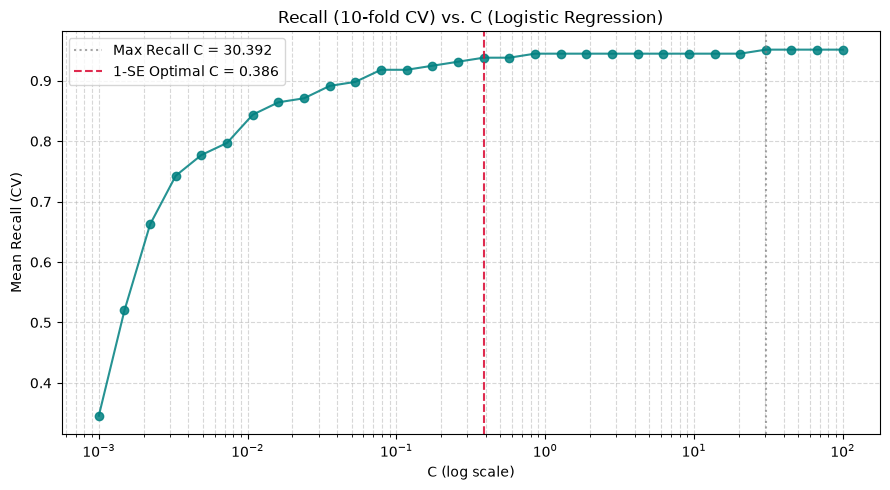

In [9]:
train_df = pd.read_csv(os.path.join(PROCESSED_DATA_DIR, "04_train_selected_features.csv"))
X_train_sel = train_df.drop(columns=["label"]).values
y_train = train_df["label"].values

MODEL_NAME = "Logistic Regression (selected features)"

param_grid = {"C": np.logspace(-3, 2, 30)}

grid_logreg, cv_results, one_se_C = tune_logreg_with_1se(
    X_train_sel, y_train, param_grid, cv_folds=CV_FOLDS, random_state=RANDOM_STATE
)

print(f"Absolute Best C (max recall): {grid_logreg.best_params_['C']:.4f}")
print(f"1-SE Rule Optimal C: {one_se_C:.4f}")
print(f"Mean Recall (1-SE C): {cv_results.loc[cv_results['param_C'] == one_se_C, 'mean_test_score'].values[0]:.4f}\n")

plot_1se_tuning_curve(
    res=cv_results, 
    best_C=grid_logreg.best_params_['C'], 
    one_se_C=one_se_C, 
    cv_folds=CV_FOLDS, 
    out_path=os.path.join(FIGURES_DIR, "05_logreg_c_tuning.png")
)

**Findings.** The recall curve hits a plateau across higher values of C. Applying the 1-SE rule selects a substantially smaller optimal C of 0.3857, applying a much stronger L2 penalty than the absolute maximum C (30.3920). This strictly regularized model maintains peak diagnostic sensitivity with a mean cross-validated recall of 0.9381. By enforcing this simpler mathematical structure, the model is prevented from overfitting to statistical noise or overly relying on redundant collinear structures, thus ensuring better generalizability.

## Evaluation

With the optimal hyperparameter `C` established, the final model is refit on the entire restricted training set. 

It is then evaluated on the held-out test set. Because this data was strictly isolated during both the feature selection and tuning phases, this step provides an unbiased estimate of the model's expected generalization performance in a simulated clinical setting.

--- Final evaluation (held-out test set) ---


,accuracy,precision,recall,f1,f2,roc_auc
Logistic Regression (selected features),0.9825,1.0,0.9531,0.976,0.9621,0.9971


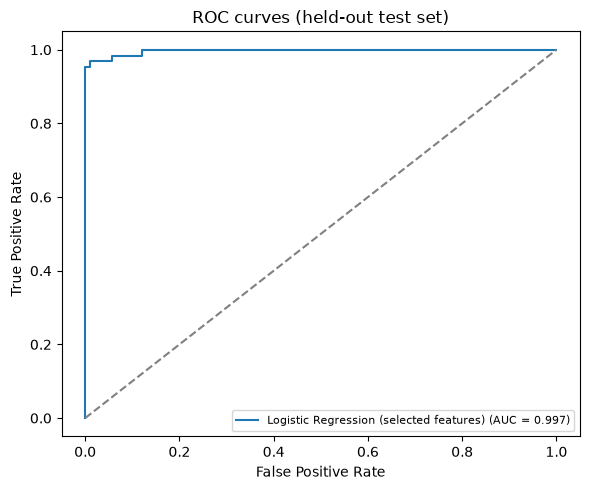

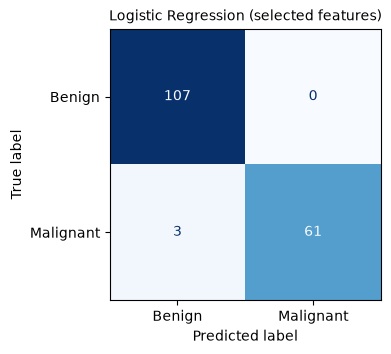

In [10]:
test_df = pd.read_csv(os.path.join(PROCESSED_DATA_DIR, "04_test_selected_features.csv"))
X_test_sel = test_df.drop(columns=["label"]).values
y_test = test_df["label"].values

best_logreg = LogisticRegression(C=one_se_C, random_state=RANDOM_STATE, max_iter=5000).fit(X_train_sel, y_train)
models_dict = {MODEL_NAME: best_logreg}

metrics_logreg = evaluate_classifier(best_logreg, X_train_sel, y_train, X_test_sel, y_test)
df_results_logreg = pd.DataFrame([metrics_logreg], index=[MODEL_NAME])
df_results_logreg.to_csv(os.path.join(RESULTS_DIR, "05_logreg_final_metrics.csv"))

print("--- Final evaluation (held-out test set) ---")
display(df_results_logreg.round(4))

plot_roc_curves(
    classifiers=models_dict, X_tr=X_train_sel, y_tr=y_train, X_te=X_test_sel, y_te=y_test,
    out_path=os.path.join(FIGURES_DIR, "05_logreg_roc_curve.png"))

plot_confusion_matrices(
    classifiers=models_dict, X_tr=X_train_sel, y_tr=y_train, X_te=X_test_sel, y_te=y_test,
    out_path=os.path.join(FIGURES_DIR, "05_logreg_confusion_matrix.png")
)

**Findings.** On the held-out test set, the 1-SE tuned model misses 3 malignant cases (recall = 0.9531), successfully preserving the clinical priority of the project. Notably, the stronger regularization eliminated all false alarms: the model correctly classified all 107 benign cases, achieving a perfect precision of 1.0. The ROC-AUC of 0.9971 confirms that the model correctly ranks malignant cases above benign ones with extreme efficiency.

## Model interpretation
 
Logistic Regression provides high interpretability through its coefficients. Since the feature space is standardized, the magnitude of each coefficient directly reflects the feature's influence on the log-odds of a malignant diagnosis.

To establish the statistical robustness of these weights, we apply bootstrap resampling (1,000 iterations). By repeatedly resampling the training data with replacement and refitting the model, we approximate the sampling distribution of the coefficients. This allows us to compute 95% confidence intervals and verify that the learned feature importances are reliable and not merely artifacts of the specific training split.

--- Logistic Regression coefficients (standardized features) ---


,coefficient,ci_low,ci_high,odds_ratio_per_SD
radius_mean,1.960,1.528,2.306,7.096
texture_worst,1.274,1.018,1.563,3.576
radius_se,1.263,0.711,1.687,3.537
concave_points_worst,0.964,0.720,1.288,2.622
concave_points_mean,0.895,0.593,1.257,2.448
symmetry_worst,0.649,0.248,0.977,1.914
smoothness_worst,0.504,0.145,0.827,1.656


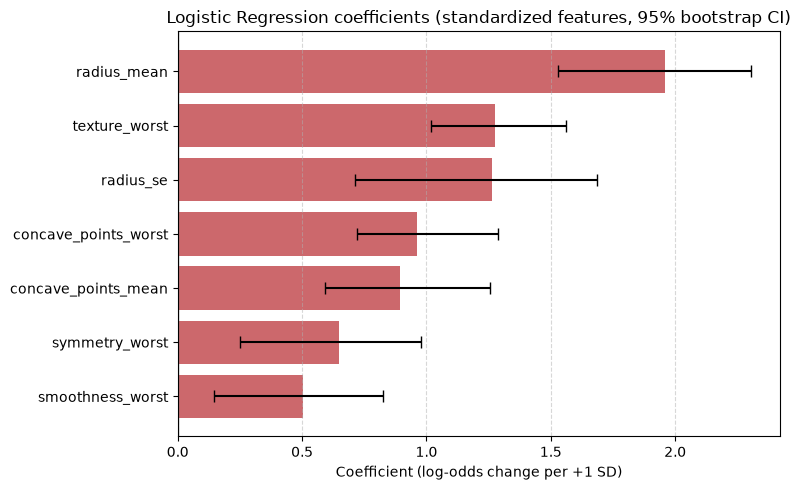

In [11]:
selected_features = train_df.drop(columns=["label"]).columns.tolist()
 
coef_table = bootstrap_logreg_coefficients(
    model=best_logreg, 
    X_train=X_train_sel, 
    y_train=y_train, 
    feature_names=selected_features, 
    n_bootstrap=1000, 
    random_state=RANDOM_STATE
)
coef_table.to_csv(os.path.join(RESULTS_DIR, "05_logreg_coefficients.csv"))
 
print("--- Logistic Regression coefficients (standardized features) ---")
display(coef_table.round(3))
 
plot_bootstrap_coefficients(
    coef_table=coef_table, 
    out_path=os.path.join(FIGURES_DIR, "05_logreg_coefficients.png")
)

**Findings.** The strict regularization enforced by the 1-SE rule establishes a stable mathematical profile where predictive weight is coherently distributed across the features. Nuclear size (`radius_mean`) acts as the dominant driver, increasing the odds of malignancy by a factor of 7.1 per standard deviation. It is supported by cellular texture (`texture_worst`) and radial variability (`radius_se`), which both increase the odds by a factor of roughly 3.5. Crucially, the bootstrap analysis confirms the reliability of this signature: none of the 95% confidence intervals cross zero, demonstrating that every single selected variable provides a statistically significant contribution to the final diagnosis.

## Discussion

By prioritizing recall and employing the 1-SE rule, the Logistic Regression model successfully maintains strict diagnostic safety while dramatically improving its statistical robustness. It misses only 3 malignant cases out of 64 on the test set. Furthermore, the stronger L2 regularization proved highly beneficial: by preventing the model from assigning arbitrary weights to correlated features, it completely eliminated false positives on the test set (precision = 1.0).

The stabilized coefficients align logically with clinical pathology. The penalty appropriately distributes the log-odds impact across correlated measurements. Nuclear size (`radius_mean`, `radius_se`) and cellular texture (`texture_worst`) remain the principal drivers of malignancy prediction, mirroring visual assessments performed by oncologists. 

**Limitations.** While the 1-SE optimization yielded perfect precision (no false alarms) on this specific held-out test set, this 1.0 metric is susceptible to sample variance and is unlikely to remain perfectly zero in a broader clinical deployment. The model's coefficients reflect mathematical decision boundaries on standardized data, not direct causal biological relationships. Finally, the data originates from a single institution, meaning external, multi-center validation is required before these specific log-odds thresholds can be generalized to other populations.